# Assignment 8

## 0.

Write a python function that takes an X and Y vector and returns an estimated  an
 from linear regression. Check your function versus one of the prewritten onek.

In [13]:
import numpy as np

def regression(x, y):
    n = len(x)
    beta1 = (n * sum(x*y) - sum(x)*sum(y)) / (n * sum(x**2) - sum(x)**2)
    beta0 = (sum(y) - beta1 * sum(x)) / n
    return beta0, beta1

In [14]:
x = np.array([1, 2, 3, 4, 5])
y = np.array([3, 5, 7, 9, 11])
beta0, beta1 = regression(x, y)
print(beta0, beta1)

1.0 2.0


In [15]:
from sklearn.linear_model import LinearRegression

def sklearn_regression(x, y):
    fit = LinearRegression().fit(x.reshape(-1, 1), y)
    intercept = fit.intercept_
    slope = fit.coef_[0]
    return intercept, slope

In [17]:
beta0, beta1 = sklearn_regression(x, y)
print(beta0, beta1)

1.0 2.0


## 1.

Using Python and basic numpy functions, fit a linear regression model to the kirby 21 dataset into colab for the left telencelphalon (predictor) to the right telencephalon (outcome). Also, do the same reversing the predictor and response relationship. Do a scatterplot of the left telencephalon (type 1 level 1) volume by the right. Do not hold out any data (there's only 21 observations).

In [19]:
import pandas as pd

kirby = pd.read_csv("kirby21.csv")
kirby

,Unnamed: 0,id,roi,volume
0,1,127,Telencephalon_L,531111
1,2,127,Telencephalon_R,543404
2,3,127,Diencephalon_L,9683
3,4,127,Diencephalon_R,9678
4,5,127,Mesencephalon,10268
...,...,...,...,...
155,156,959,Diencephalon_R,9143
156,157,959,Mesencephalon,10470
157,158,959,Metencephalon,142318
158,159,959,Myelencephalon,4508


In [29]:
kirby_telencephalon_left = kirby[kirby["roi"] == "Telencephalon_L"]
kirby_telencephalon_right = kirby[kirby["roi"] == "Telencephalon_R"]

kirby_telencephalon = pd.merge(kirby_telencephalon_left[["id", "volume"]], kirby_telencephalon_right[["id", "volume"]],
                               on="id", suffixes=("_left", "_right"))
kirby_telencephalon

,id,volume_left,volume_right
0,127,531111,543404
1,142,545603,552216
2,239,483107,490805
3,346,558849,568830
4,422,509945,518902
5,492,538936,541024
6,501,506151,516742
7,505,457862,461817
8,656,551654,570542
9,679,482556,490654


In [31]:
x = kirby_telencephalon["volume_left"].to_numpy(dtype=float)
y = kirby_telencephalon["volume_right"].to_numpy(dtype=float)
beta0, beta1 = regression(x, y)
print(beta0, beta1)

-13875.94479942359 1.0442415398322409


In [32]:
beta0, beta1 = regression(y, x)
print(beta0, beta1)

17150.431045804173 0.9500552111008127


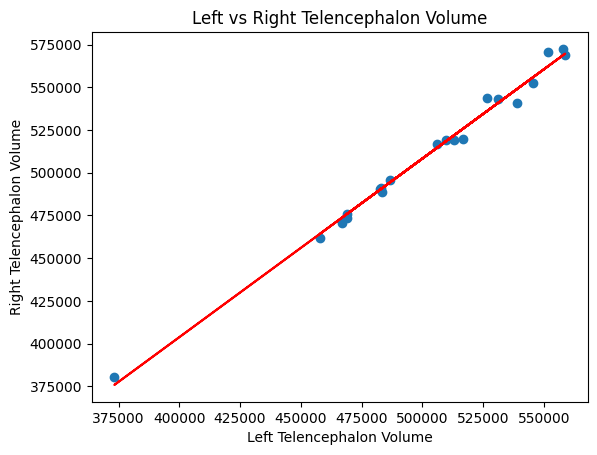

In [36]:
import matplotlib.pyplot as plt

beta0, beta1 = regression(x, y)

plt.scatter(x, y)
plt.plot(x, beta0 + (beta1 * x), color="red")
plt.xlabel("Left Telencephalon Volume")
plt.ylabel("Right Telencephalon Volume")
plt.title("Left vs Right Telencephalon Volume")
plt.show()

## 2.

Consider a regression through the origin model Y=BX . What would be the impact on the estimate of B if we replaced X by cX where c is a positive constant?

Regression through the origin is modeled by $Y = BX$

The least squares of B is $B = \frac{\sum_i X_i Y_i}{\sum_i X_i ^2}$

Replacing $X_i$ with $cX_i$, $B_{\text{new}} = \frac{\sum_i cX_i Y_i}{\sum_i (cX_i) ^2}=\frac{\sum_i c X_iY_i}{\sum_i c^2 X_i^2}=\frac{c\sum_i X_iY_i}{c^2\sum_i X_i^2}=\frac{1}{c}\frac{\sum_i X_iY_i}{\sum_i X_i^2}$

$Y_{\text{new}} = B_{\text{new}}X= \frac{1}{c}BX$

$B_{\text{new}} = \frac{1}{c}B$

Mupltiplying $X$ by a positive constant factor $c$ divides the estimated regression by $c$.

## 3.

Let  $X_i$ be a group indicator so that $x_i = I\left( i \in G_1 \right)$ I.e. takes the value 1 when $i$ is in group 1 and 0 if $i$ is in group 0. Consider optimizing $\sum_i \left( Y_i - \beta_0 - \beta_1 X_i \right)^2$. If $\hat Y = \hat \beta_0 + \hat \beta_1 X$, argue that $\hat Y$
 is the group mean for group 1 if $X=1$
 and the group mean for group 0 if $X=0$. 

Linear regression with binary group indicator is modeled by $Y_i = \beta_0 + \beta_1 X_i$ where $X_i=0$ for group 0 and $X_i=1$ for group 1.

Optimize by minimizing the sum of squared errors: $\frac{1}{n}\sum_i(Y_i-\beta_0-\beta_1X_i)^2=\frac{1}{n}\left[\sum_{i\in G_0}(Y_i-\beta_0)^2+\sum_{i\in G_1}(Y_i-\beta_0-\beta_1)^2\right]$

For group 0, $\hat\beta_0=\bar Y_0$ and for group 1, $\hat\beta_0+\hat\beta_1=\bar Y_1$

$\hat\beta_1=\bar Y_1-\bar Y_0$

For $X=0$, $\hat Y=\bar Y_0+(\bar Y_1-\bar Y_0)(0)=\bar Y_0$

For $X=1$, $\hat Y=\bar Y_0+(\bar Y_1-\bar Y_0)(1)=\bar Y_1$

## 4.

Argue that if you take the vectors $Y$
 and$X$
 and divide them by their standard deviations (respectively), the slope for either regressin$Y$ 
 $X$n  $X$or $Y$ on 
 is simply the correlation.

For linear regression with an intercept the estimated slope when regressing $Y$ on $X$ is modeled by $\hat\beta_1=\frac{\mathrm{Cov}(X,Y)}{\mathrm{Var}(X)}$

$\mathrm{Cov}(X,Y)=r_{XY}s_Xs_Y$

$\hat\beta_1=\frac{r_{XY}s_Xs_Y}{s_X^2}=r_{XY}\frac{s_Y}{s_X}$

If you divide the variables by their standard deviations $X^*=\frac{X}{s_X}$, $Y^*=\frac{Y}{s_Y}$, then $X^*$ and $Y^*$ have standard deviations $=1$

Correlation does not change when by dividing variables by positive constants so 

for regressing $X$ on $Y$, $\hat\beta_1^*=r_{XY}\frac{1}{1}=r_{XY}$ and 

for regression $Y$ on $X$, $\hat\beta_1^*=r_{XY}\frac{1}{1}=r_{XY}$

so the slopes are equal to the correlations.